# DAZONE 2026 — Class Flipping Uplift Models only

Notebook này là bản tích hợp ý tưởng từ paper **Class Flipping for uplift modeling / HTE estimation on imbalanced RCT data** vào quy trình train model.

Đã loại bỏ quá trình train 2 model gốc:
- ~~INT_RF~~
- ~~UPLIFT_RF_CIT~~

Chỉ giữ lại các model sau khi tích hợp Class Flipping:
- **CLASS_FLIP_INT_RF**: Interaction S-Learner Random Forest + class flipping trên train fold.
- **CLASS_FLIP_UPLIFT_RF_CIT**: CausalML Uplift Random Forest criterion **CIT** + class flipping trên train fold.

Nguyên tắc tích hợp:
- Chỉ class flipping trên **train fold**.
- Không class flipping trên validation fold / test.
- Với mỗi target cash/card, tính majority class riêng trong treatment/control của train fold.
- Flip một phần majority class theo hệ số `k` của paper.
- Score uplift dự đoán trên label đã flip được hiệu chỉnh tuyến tính về scale uplift gốc.
- Model selection vẫn dựa trên **Qini_coefficient_total = qini_cash + qini_card**.

Cách chạy feature dropping:
- `COL_IDX = None`: baseline, không drop feature nào.
- `COL_IDX = 0`: drop 1 feature theo ID trong `FEATURE_DROP_PRIORITY_LIST`.
- `COL_IDX = [2, 3, 4, 5]`: drop nhiều feature cùng lúc.
- `COL_IDX = list(range(2, 6))`: drop liên tiếp ID 2, 3, 4, 5.
- `COL_IDX = "2:6"`: drop liên tiếp ID 2, 3, 4, 5, giống slicing Python.
- `COL_IDX = ["cli_age", "risk_grp"]`: drop trực tiếp theo tên feature gốc.

Với feature one-hot/encoded, notebook sẽ drop toàn bộ nhóm cột sinh ra từ feature gốc. Ví dụ `cli_job` sẽ drop các cột `cli_job_*`.


In [1]:
# ============================================================
# 0. MINIMAL ENVIRONMENT SETUP
# ============================================================
# Chỉ CLASS_FLIP_UPLIFT_RF_CIT cần package causalml.
# Mặc định không cài gì để notebook gọn và tránh tốn thời gian setup trên Kaggle.
# Nếu Kaggle báo thiếu causalml, bật RUN_INSTALL_CAUSALML=True rồi chạy lại cell này.

RUN_INSTALL_CAUSALML = True

import importlib.util
import subprocess
import sys


def is_installed(import_name: str) -> bool:
    return importlib.util.find_spec(import_name) is not None


if RUN_INSTALL_CAUSALML and not is_installed("causalml"):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "causalml"])
elif RUN_INSTALL_CAUSALML:
    print("OK: causalml already installed")
else:
    print("RUN_INSTALL_CAUSALML=False -> skip install")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 70.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 3.7 MB/s eta 0:00:00


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import time
import warnings
from pathlib import Path

# Giới hạn thread để ổn định runtime trên Kaggle/CPU.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
N_JOBS = 4

# Random Forest base learner cho CLASS_FLIP_INT_RF.
# Không dùng class_weight vì class flipping đã xử lý imbalance ở train fold;
# thêm class_weight có thể làm méo xác suất flipped-response.
RF_N_ESTIMATORS = 320
RF_MAX_DEPTH = 9
RF_MIN_SAMPLES_LEAF = 80
RF_MAX_FEATURES = "sqrt"

# Uplift Random Forest CIT cho CLASS_FLIP_UPLIFT_RF_CIT.
CAUSALML_RF_N_ESTIMATORS = 80
CAUSALML_RF_MAX_DEPTH = 5
CAUSALML_RF_MIN_SAMPLES_LEAF = 120
CAUSALML_RF_MIN_SAMPLES_TREATMENT = 40
CAUSALML_RF_MAX_FEATURES_CAP = 12
CAUSALML_CRITERION = "CIT"

# Class flipping config.
CLASS_FLIP_EPS = 1e-8
SELECTED_MODEL_NAMES = ["CLASS_FLIP_INT_RF", "CLASS_FLIP_UPLIFT_RF_CIT"]

try:
    from causalml.inference.tree import UpliftRandomForestClassifier
    HAS_CAUSALML = True
    print("causalml: available")
except Exception as e:
    HAS_CAUSALML = False
    print("causalml unavailable -> CLASS_FLIP_UPLIFT_RF_CIT sẽ bị skip:", repr(e))


Failed to import duecredit due to No module named 'duecredit'


causalml: available


## 2. Load dữ liệu + feature dropping

In [3]:
# ============================================================
# 2. LOAD DATA + FEATURE DROPPING CONFIG
# ============================================================

FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# Tùy chỉnh feature dropping:
#   None -> baseline, không drop feature nào.
#   int  -> drop 1 feature theo ID. Ví dụ: COL_IDX = 0.
#   list/tuple/set/range -> drop nhiều feature. Ví dụ: COL_IDX = [2, 3, 4, 5].
#   list(range(a, b)) -> drop liên tiếp ID a..b-1. Ví dụ: list(range(2, 6)) = 2,3,4,5.
#   string "a:b" -> drop liên tiếp ID a..b-1. Ví dụ: "2:6" = 2,3,4,5.
#   string/list tên feature -> drop trực tiếp theo tên feature gốc. Ví dụ: ["cli_age", "risk_grp"].
#
# Ví dụ chạy:
#   COL_IDX = None
#   COL_IDX = 0
#   COL_IDX = [2, 3]
#   COL_IDX = list(range(2, 6))
#   COL_IDX = "2:6"
COL_IDX = None

feat_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
tgt_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"

TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]


def normalize_feature_drop_selection(selection):
    """Chuẩn hóa cấu hình drop feature.

    Trả về:
    - drop_ids: list ID trong FEATURE_DROP_PRIORITY_LIST.
    - drop_base_cols: list tên feature gốc cần drop.

    Hỗ trợ:
    - None
    - int
    - list/tuple/set/range chứa int hoặc tên feature
    - string "a:b" để drop ID a..b-1
    - string tên feature gốc
    """
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                start, stop = int(m.group(1)), int(m.group(2))
                return list(range(start, stop))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError(
            "COL_IDX chỉ hỗ trợ None, int, range, slice, str, "
            "hoặc list/tuple/set chứa int/tên feature."
        )

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        elif isinstance(item, str):
            base_col = item.strip()
            if base_col not in FEATURE_DROP_PRIORITY_LIST:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong df_feature.")
                idx = None
            else:
                idx = FEATURE_DROP_PRIORITY_LIST.index(base_col)
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        else:
            raise TypeError(f"COL_IDX chứa phần tử không hợp lệ: {item!r}")

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    """Match cột gốc và các cột one-hot/encoded sinh ra từ feature gốc."""
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df):
    """Return W: 1 = Cash strategy, 0 = Card strategy."""
    if TREAT_COL_BINARY in feature_df.columns:
        return feature_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY
    if TREAT_COL_RAW not in feature_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong df_feature.csv")

    s = feature_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int).to_numpy(), TREAT_COL_RAW

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")
    return mapped.astype(int), TREAT_COL_RAW




feat = pd.read_csv(feat_path)
tgt = pd.read_csv(tgt_path)

W, TREAT_COL = encode_treatment_cash(feat)
Y_cash = tgt[TARGET_CASH].astype(int).to_numpy()
Y_card = tgt[TARGET_CARD].astype(int).to_numpy()

ID_COL = next((col for col in ID_CANDIDATES if col in feat.columns), None)
FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS = normalize_feature_drop_selection(COL_IDX)
FEATURE_DROP_BASE_COL = None if len(FEATURE_DROP_BASE_COLS) == 0 else "|".join(FEATURE_DROP_BASE_COLS)
FEATURE_DROP_COL_IDX = None if len(FEATURE_DROP_IDXS) == 0 else "|".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)

drop_cols_in_feat = []
for base_col in FEATURE_DROP_BASE_COLS:
    drop_cols_in_feat.extend(match_base_feature_columns(feat.columns, base_col))
# Deduplicate while preserving order.
drop_cols_in_feat = list(dict.fromkeys(drop_cols_in_feat))

index_like_cols = [c for c in feat.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
exclude_cols = set(drop_cols_in_feat + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
if ID_COL is not None:
    exclude_cols.add(ID_COL)

FEAT_COLS = [col for col in feat.columns if col not in exclude_cols]
X_df = feat[FEAT_COLS].copy()
X = X_df.to_numpy(dtype=np.float32)

w_cash = (W == 1).astype(int)
w_card = (W == 0).astype(int)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped df_feature columns ({len(drop_cols_in_feat)}): {drop_cols_in_feat}")
print("=" * 80)

print(f"N={len(X):,} | features={X.shape[1]}")
print(f"Treatment Cash: {W.sum():,} ({W.mean():.2%}) | Card: {(1-W).sum():,} ({(1-W).mean():.2%})")
print(f"Cash target rate: {Y_cash.mean():.4%} | Card target rate: {Y_card.mean():.4%}")
print("Feature NaN total:", int(pd.isna(X_df).sum().sum()))


FEATURE DROPPING: baseline, không drop feature nào
N=136,992 | features=62
Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Cash target rate: 5.9186% | Card target rate: 2.7111%
Feature NaN total: 0


In [4]:
# ============================================================
# 3. OPTIONAL TEST FEATURE LOADING
# ============================================================
# Notebook chỉ dùng test file đã clean/one-hot tương thích với df_feature.csv.
# Nếu không có test feature đã clean, phần submission sẽ tự skip.


def find_optional_test_feature():
    names = ["df_feature_test.csv", "test_feature.csv", "X_test.csv", "test.csv"]
    roots = [p for p in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
             if p.exists() and str(p.resolve()) not in ["/", "/mnt"]]
    for root in roots:
        for name in names:
            direct = root / name
            if direct.exists():
                return direct
            try:
                hits = list(root.rglob(name))
                if hits:
                    return sorted(hits, key=lambda p: len(str(p)))[0]
            except Exception:
                pass
    return None


def build_test_matrix(test_feature_path):
    test_feat = pd.read_csv(test_feature_path)
    test_id_col = next((col for col in ID_CANDIDATES if col in test_feat.columns), None)
    test_id = make_id_series(test_feat, id_col=test_id_col)

    # Align đúng FEAT_COLS của train: thiếu cột thì fill 0, thừa cột thì bỏ.
    X_test_df = test_feat.reindex(columns=FEAT_COLS, fill_value=0).copy()
    return test_feat, test_id, X_test_df, X_test_df.to_numpy(dtype=np.float32)


test_path = find_optional_test_feature()
if test_path is None:
    test_feat = None
    test_id = None
    X_test_df = None
    X_test = None
    print("Không tìm thấy test feature đã clean -> skip submission.")
else:
    test_feat, test_id, X_test_df, X_test = build_test_matrix(test_path)
    print("Test feature path:", test_path)
    print(f"X_test shape={X_test.shape}")


Không tìm thấy test feature đã clean -> skip submission.


In [5]:
# ============================================================
# 4. LEAKAGE AUDIT
# ============================================================
FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if ID_COL is not None:
    FORBIDDEN_FEATURE_COLS.add(ID_COL)

forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

assert TARGET_CASH not in FEAT_COLS and TARGET_CARD not in FEAT_COLS, "DATA LEAKAGE: target bị đưa vào X"
assert TREAT_COL_BINARY not in FEAT_COLS and TREAT_COL_RAW not in FEAT_COLS, "DATA LEAKAGE: treatment bị đưa vào X"
if ID_COL is not None:
    assert ID_COL not in FEAT_COLS, "DATA LEAKAGE/RISK: ID bị đưa vào X"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(feat.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(feat.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})

print("Leakage audit: PASSED")
display(feature_drop_audit)


Leakage audit: PASSED


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


## 3. Qini metric + fold cố định

In [6]:
# ============================================================
# 5. QINI METRIC + FIXED FOLDS
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def make_fold_id(w_event, y):
    key = (np.asarray(w_event, dtype=int) * 2 + np.asarray(y, dtype=int)).astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.zeros(len(y), dtype=int)
    dummy_x = np.zeros(len(y))
    for fold, (_, va) in enumerate(skf.split(dummy_x, key), 1):
        fold_id[va] = fold
    return fold_id


fold_ids = {
    "cash": make_fold_id(w_cash, Y_cash),
    "card": make_fold_id(w_card, Y_card),
}

print("Fold distribution cash target:", pd.Series(fold_ids["cash"]).value_counts().sort_index().to_dict())
print("Fold distribution card target:", pd.Series(fold_ids["card"]).value_counts().sort_index().to_dict())


Fold distribution cash target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}
Fold distribution card target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}


## 4. Model helpers: Class Flipping + uplift models

In [7]:
# ============================================================
# 6. MODEL HELPERS + CLASS FLIPPING
# ============================================================
class ConstantClassifier:
    def __init__(self, value):
        self.value = float(value)
        self.classes_ = np.array([0, 1])

    def fit(self, X, y, sample_weight=None):
        return self

    def predict_proba(self, X):
        p = np.full(len(X), self.value, dtype=float)
        p = np.clip(p, 0.0, 1.0)
        return np.c_[1 - p, p]


def make_rf_classifier(seed=SEED):
    return RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        max_features=RF_MAX_FEATURES,
        class_weight=None,
        n_jobs=N_JOBS,
        random_state=seed,
    )


def fit_classifier(X_train, y_train, sample_weight=None, seed=SEED):
    y_train = np.asarray(y_train, dtype=int)
    if len(y_train) == 0 or len(np.unique(y_train)) < 2:
        return ConstantClassifier(float(y_train.mean()) if len(y_train) else 0.0)

    model = make_rf_classifier(seed=seed)
    if sample_weight is None:
        model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train, sample_weight=np.asarray(sample_weight, dtype=np.float32))
    return model


def predict_classifier(model, X_pred):
    proba = np.asarray(model.predict_proba(X_pred))
    if proba.ndim == 1:
        return np.clip(proba.astype(float), 0.0, 1.0)
    if proba.shape[1] == 1:
        classes = getattr(model, "classes_", np.array([1]))
        return np.full(len(X_pred), float(classes[0] == 1))
    classes = list(getattr(model, "classes_", [0, 1]))
    idx = classes.index(1) if 1 in classes else -1
    return proba[:, idx].astype(float)


def fold_iter(target_name):
    fid = fold_ids[target_name]
    for fold in range(1, N_SPLITS + 1):
        va = np.where(fid == fold)[0]
        tr = np.where(fid != fold)[0]
        yield fold, tr, va


def get_target_arrays(target_name):
    if target_name == "cash":
        # Event treatment = Cash, control = Card.
        return Y_cash, w_cash, "CASH"
    if target_name == "card":
        # Event treatment = Card, control = Cash.
        return Y_card, w_card, "CARD"
    raise ValueError(target_name)


def print_fold_metric(fold, target_name, y, w_event, va, pred):
    met = qini_metrics(y[va], w_event[va], pred)
    print(f"  fold {fold}: Qini_coefficient_{target_name}={met['qini_norm']:+.5f} | Q_ratio={met['qini_ratio']:+.4f}")
    return met


def extract_uplift_prediction(pred_raw):
    """Chuẩn hóa output từ causalml về vector uplift 1D."""
    if isinstance(pred_raw, pd.DataFrame):
        num = pred_raw.select_dtypes(include=[np.number])
        for c in ["uplift", "treatment_effect", "maxTreatmentEffect", "recommended_treatment_effect"]:
            if c in num.columns:
                return num[c].to_numpy(dtype=float)
        return num.iloc[:, -1].to_numpy(dtype=float)

    arr = np.asarray(pred_raw)
    if arr.ndim == 1:
        return arr.astype(float)
    if arr.shape[1] >= 2:
        return (arr[:, 1] - arr[:, 0]).astype(float)
    return arr[:, 0].astype(float)


def _majority_class_binary(y):
    y = np.asarray(y, dtype=int)
    counts = np.bincount(y, minlength=2)
    return int(counts[1] >= counts[0])


def build_class_flipping_plan(y_train, w_event_train):
    """Tạo kế hoạch class flipping theo paper.

    w_event_train = 1 là treatment/event arm của target đang xét,
    w_event_train = 0 là control arm.

    Nếu majority class ở treatment/control là m_T/m_C, flip class đó với xác suất 1-k.
    Với score uplift học trên label đã flip:
        tau_flipped = k * tau_original + offset
    nên:
        tau_original = (tau_flipped - offset) / k
    """
    y_train = np.asarray(y_train, dtype=int)
    w_event_train = np.asarray(w_event_train, dtype=int)

    mask_t = w_event_train == 1
    mask_c = w_event_train == 0
    if mask_t.sum() == 0 or mask_c.sum() == 0:
        return {
            "k": 1.0,
            "flip_probability": 0.0,
            "treatment_majority_class": 0,
            "control_majority_class": 0,
            "offset": 0.0,
            "p_major_treatment": 1.0,
            "p_major_control": 1.0,
        }

    m_t = _majority_class_binary(y_train[mask_t])
    m_c = _majority_class_binary(y_train[mask_c])
    p_major_t = float(np.mean(y_train[mask_t] == m_t))
    p_major_c = float(np.mean(y_train[mask_c] == m_c))
    denom = max(p_major_t + p_major_c, CLASS_FLIP_EPS)
    k = float(np.clip(1.0 / denom, CLASS_FLIP_EPS, 1.0))
    flip_probability = float(1.0 - k)

    # p'_g = k * p_g + b_g. Nếu flip class 0 thì b_g = 1-k, nếu flip class 1 thì b_g = 0.
    b_t = (1.0 - k) if m_t == 0 else 0.0
    b_c = (1.0 - k) if m_c == 0 else 0.0
    offset = float(b_t - b_c)

    return {
        "k": k,
        "flip_probability": flip_probability,
        "treatment_majority_class": int(m_t),
        "control_majority_class": int(m_c),
        "offset": offset,
        "p_major_treatment": p_major_t,
        "p_major_control": p_major_c,
    }


def apply_class_flipping(y_train, w_event_train, plan, seed=SEED):
    """Flip đúng một phần majority class trong từng group treatment/control của train fold."""
    y_train = np.asarray(y_train, dtype=int)
    w_event_train = np.asarray(w_event_train, dtype=int)
    y_flip = y_train.copy()
    flip_probability = float(plan.get("flip_probability", 0.0))
    if flip_probability <= 0:
        return y_flip

    rng = np.random.default_rng(seed)
    for group_value, key in [(1, "treatment_majority_class"), (0, "control_majority_class")]:
        majority_class = int(plan[key])
        idx = np.where((w_event_train == group_value) & (y_train == majority_class))[0]
        if len(idx) == 0:
            continue
        n_flip = int(np.round(flip_probability * len(idx)))
        n_flip = max(0, min(n_flip, len(idx)))
        if n_flip == 0:
            continue
        flip_idx = rng.choice(idx, size=n_flip, replace=False)
        y_flip[flip_idx] = 1 - majority_class
    return y_flip


def correct_flipped_uplift(pred_flipped, plan):
    """Hiệu chỉnh tuyến tính score uplift từ label đã flip về scale uplift gốc."""
    pred_flipped = np.asarray(pred_flipped, dtype=float)
    k = max(float(plan.get("k", 1.0)), CLASS_FLIP_EPS)
    offset = float(plan.get("offset", 0.0))
    return (pred_flipped - offset) / k


def print_class_flipping_info(fold, y_original, y_flipped, plan):
    n_changed = int(np.sum(np.asarray(y_original) != np.asarray(y_flipped)))
    print(
        f"  fold {fold}: class_flip "
        f"k={plan['k']:.4f} | flip_prob={plan['flip_probability']:.4f} | "
        f"majority(T/C)={plan['treatment_majority_class']}/{plan['control_majority_class']} | "
        f"changed={n_changed:,} | y_rate {np.mean(y_original):.4%}->{np.mean(y_flipped):.4%}"
    )


In [8]:
# ============================================================
# 7. CLASS_FLIP_INT_RF — Interaction S-Learner + Class Flipping
# ============================================================
def run_class_flip_int_rf(target_name, X_test=None):
    y, w_event, label = get_target_arrays(target_name)
    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None

    print(f"\n[{label}] CLASS_FLIP_INT_RF")
    for fold, tr, va in fold_iter(target_name):
        plan = build_class_flipping_plan(y[tr], w_event[tr])
        y_tr_flip = apply_class_flipping(y[tr], w_event[tr], plan, seed=SEED + 1000 + fold)
        print_class_flipping_info(fold, y[tr], y_tr_flip, plan)

        # X_aug = [X, treatment_event_flag, X * treatment_event_flag]
        wt = w_event[tr].astype(np.float32)[:, None]
        Xtr_aug = np.c_[X[tr], wt, X[tr] * wt]

        Xva_event = np.c_[X[va], np.ones((len(va), 1), dtype=np.float32), X[va]]
        Xva_control = np.c_[X[va], np.zeros((len(va), 1), dtype=np.float32), np.zeros_like(X[va])]

        model = fit_classifier(Xtr_aug, y_tr_flip, sample_weight=None, seed=SEED + fold)
        pred_flip = predict_classifier(model, Xva_event) - predict_classifier(model, Xva_control)
        pred = correct_flipped_uplift(pred_flip, plan)
        oof[va] = pred

        if X_test is not None:
            Xte_event = np.c_[X_test, np.ones((len(X_test), 1), dtype=np.float32), X_test]
            Xte_control = np.c_[X_test, np.zeros((len(X_test), 1), dtype=np.float32), np.zeros_like(X_test)]
            pred_test_flip = predict_classifier(model, Xte_event) - predict_classifier(model, Xte_control)
            test_score += correct_flipped_uplift(pred_test_flip, plan) / N_SPLITS

        print_fold_metric(fold, target_name, y, w_event, va, pred)
        del model, y_tr_flip
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)
    print(f"  OOF: Qini_coefficient_{target_name}={full_met['qini_norm']:+.5f} | Q_ratio={full_met['qini_ratio']:+.4f}")
    return oof, test_score


In [9]:
# ============================================================
# 8. CLASS_FLIP_UPLIFT_RF_CIT — CausalML Uplift RF CIT + Class Flipping
# ============================================================
def make_causalml_rf(seed):
    base_kwargs = dict(
        n_estimators=CAUSALML_RF_N_ESTIMATORS,
        max_features=min(CAUSALML_RF_MAX_FEATURES_CAP, X.shape[1]),
        max_depth=CAUSALML_RF_MAX_DEPTH,
        min_samples_leaf=CAUSALML_RF_MIN_SAMPLES_LEAF,
        min_samples_treatment=CAUSALML_RF_MIN_SAMPLES_TREATMENT,
        evaluationFunction=CAUSALML_CRITERION,
        control_name="control",
    )
    # CausalML version khác nhau có thể khác signature; thử từ đầy đủ đến tối giản.
    for extra_kwargs in [
        {"n_jobs": N_JOBS, "random_state": seed},
        {"random_state": seed},
        {"n_jobs": N_JOBS},
        {},
    ]:
        try:
            return UpliftRandomForestClassifier(**base_kwargs, **extra_kwargs)
        except TypeError:
            continue
    return UpliftRandomForestClassifier(**base_kwargs)


def run_class_flip_uplift_rf_cit(target_name, X_test=None):
    if not HAS_CAUSALML:
        raise ImportError("causalml is not installed")

    y, w_event, label = get_target_arrays(target_name)
    treatment_labels = np.where(w_event == 1, "treatment", "control")
    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None

    print(f"\n[{label}] CLASS_FLIP_UPLIFT_RF_CIT")
    for fold, tr, va in fold_iter(target_name):
        plan = build_class_flipping_plan(y[tr], w_event[tr])
        y_tr_flip = apply_class_flipping(y[tr], w_event[tr], plan, seed=SEED + 2000 + fold)
        print_class_flipping_info(fold, y[tr], y_tr_flip, plan)

        model = make_causalml_rf(seed=SEED + fold)
        model.fit(X[tr], treatment=treatment_labels[tr], y=y_tr_flip)

        pred_flip = extract_uplift_prediction(model.predict(X[va]))
        pred = correct_flipped_uplift(pred_flip, plan)
        oof[va] = pred

        if X_test is not None:
            pred_test_flip = extract_uplift_prediction(model.predict(X_test))
            test_score += correct_flipped_uplift(pred_test_flip, plan) / N_SPLITS

        print_fold_metric(fold, target_name, y, w_event, va, pred)
        del model, y_tr_flip
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)
    print(f"  OOF: Qini_coefficient_{target_name}={full_met['qini_norm']:+.5f} | Q_ratio={full_met['qini_ratio']:+.4f}")
    return oof, test_score


## 5. Chạy các model sau khi tích hợp Class Flipping

In [10]:
# ============================================================
# 9. RUN CLASS-FLIPPING MODELS ONLY
# ============================================================
scores_oof = {"cash": {}, "card": {}}
scores_test = {"cash": {}, "card": {}}
run_log = []


def add_pair_result(model_name, cash_tuple, card_tuple, model_type):
    cash_oof, cash_te = cash_tuple
    card_oof, card_te = card_tuple

    scores_oof["cash"][model_name] = cash_oof
    scores_oof["card"][model_name] = card_oof
    if cash_te is not None:
        scores_test["cash"][model_name] = cash_te
    if card_te is not None:
        scores_test["card"][model_name] = card_te

    row = summarize_one_model(model_name)
    print(f"\n>>> Summary after {model_name}: CASH / CARD / TOTAL")
    display(row.round(6))


def summarize_one_model(model_name):
    row = {"model": model_name}
    row["Qini_coefficient_cash"] = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])["qini_norm"]
    row["Qini_coefficient_card"] = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])["qini_norm"]
    row["Qini_coefficient_total"] = row["Qini_coefficient_cash"] + row["Qini_coefficient_card"]
    return pd.DataFrame([row])


start_all = time.time()

# 1) CLASS_FLIP_INT_RF
try:
    t0 = time.time()
    cash_tuple = run_class_flip_int_rf("cash", X_test=X_test)
    card_tuple = run_class_flip_int_rf("card", X_test=X_test)
    add_pair_result("CLASS_FLIP_INT_RF", cash_tuple, card_tuple, model_type="class_flip_interaction_rf")
    run_log.append({"model": "CLASS_FLIP_INT_RF", "minutes": (time.time() - t0) / 60, "type": "class_flip_interaction_rf"})
except Exception as e:
    print("Skip CLASS_FLIP_INT_RF due to error:", repr(e))
    run_log.append({"model": "CLASS_FLIP_INT_RF", "minutes": np.nan, "type": "class_flip_interaction_rf", "error": repr(e)})
    gc.collect()

# 2) CLASS_FLIP_UPLIFT_RF_CIT
try:
    if not HAS_CAUSALML:
        raise ImportError("causalml is not installed")
    t0 = time.time()
    cash_tuple = run_class_flip_uplift_rf_cit("cash", X_test=X_test)
    card_tuple = run_class_flip_uplift_rf_cit("card", X_test=X_test)
    add_pair_result("CLASS_FLIP_UPLIFT_RF_CIT", cash_tuple, card_tuple, model_type="class_flip_direct_uplift_causalml")
    run_log.append({"model": "CLASS_FLIP_UPLIFT_RF_CIT", "minutes": (time.time() - t0) / 60, "type": "class_flip_direct_uplift_causalml"})
except Exception as e:
    print("Skip CLASS_FLIP_UPLIFT_RF_CIT due to error:", repr(e))
    run_log.append({"model": "CLASS_FLIP_UPLIFT_RF_CIT", "minutes": np.nan, "type": "class_flip_direct_uplift_causalml", "error": repr(e)})
    gc.collect()

print(f"\nTotal runtime: {(time.time() - start_all) / 60:.1f} minutes")
print("Finished models:", list(scores_oof["cash"].keys()))



[CASH] CLASS_FLIP_INT_RF
  fold 1: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9183%->50.0205%
  fold 1: Qini_coefficient_cash=+0.04236 | Q_ratio=+1.6456
  fold 2: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,334 | y_rate 5.9183%->50.0214%
  fold 2: Qini_coefficient_cash=+0.04364 | Q_ratio=+1.6643
  fold 3: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9191%->50.0210%
  fold 3: Qini_coefficient_cash=+0.05560 | Q_ratio=+1.8373
  fold 4: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9191%->50.0210%
  fold 4: Qini_coefficient_cash=+0.06257 | Q_ratio=+1.9422
  fold 5: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,334 | y_rate 5.9182%->50.0210%
  fold 5: Qini_coefficient_cash=+0.05839 | Q_ratio=+1.8731
  OOF: Qini_coefficient_cash=+0.05161 | Q_ratio=+1.7796

[CARD] CLASS_FLIP_INT_RF
  fold 1: class_flip k=0.5140 | 

,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,CLASS_FLIP_INT_RF,0.051609,0.012721,0.064329



[CASH] CLASS_FLIP_UPLIFT_RF_CIT
  fold 1: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9183%->50.0205%
  fold 1: Qini_coefficient_cash=+0.03806 | Q_ratio=+1.5800
  fold 2: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,334 | y_rate 5.9183%->50.0214%
  fold 2: Qini_coefficient_cash=+0.02648 | Q_ratio=+1.4031
  fold 3: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9191%->50.0210%
  fold 3: Qini_coefficient_cash=+0.05890 | Q_ratio=+1.8869
  fold 4: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,333 | y_rate 5.9191%->50.0210%
  fold 4: Qini_coefficient_cash=+0.03970 | Q_ratio=+1.5978
  fold 5: class_flip k=0.5312 | flip_prob=0.4688 | majority(T/C)=0/0 | changed=48,334 | y_rate 5.9182%->50.0210%
  fold 5: Qini_coefficient_cash=+0.04685 | Q_ratio=+1.7005
  OOF: Qini_coefficient_cash=+0.04242 | Q_ratio=+1.6408

[CARD] CLASS_FLIP_UPLIFT_RF_CIT
  fold 1: class_fl

,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,CLASS_FLIP_UPLIFT_RF_CIT,0.042424,0.013428,0.055852



Total runtime: 12.8 minutes
Finished models: ['CLASS_FLIP_INT_RF', 'CLASS_FLIP_UPLIFT_RF_CIT']


## 6. Summary + fold mean

In [11]:
# ============================================================
# 10. SUMMARY TABLES
# ============================================================
def summarize_scores_all():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        cash_met = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])
        card_met = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])
        rows.append({
            "model": model_name,
            "Qini_coefficient_cash": cash_met["qini_norm"],
            "Qini_coefficient_card": card_met["qini_norm"],
            "Qini_coefficient_total": cash_met["qini_norm"] + card_met["qini_norm"],
        })
    if not rows:
        return pd.DataFrame(columns=["model", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"])
    return pd.DataFrame(rows).sort_values("Qini_coefficient_total", ascending=False).reset_index(drop=True)


def make_fold_qini_table():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        for fold in range(1, N_SPLITS + 1):
            idx_cash = fold_ids["cash"] == fold
            idx_card = fold_ids["card"] == fold
            cash_qini = qini_metrics(Y_cash[idx_cash], w_cash[idx_cash], scores_oof["cash"][model_name][idx_cash])["qini_norm"]
            card_qini = qini_metrics(Y_card[idx_card], w_card[idx_card], scores_oof["card"][model_name][idx_card])["qini_norm"]
            rows.append({
                "model": model_name,
                "fold": fold,
                "Qini_coefficient_cash": cash_qini,
                "Qini_coefficient_card": card_qini,
                "Qini_coefficient_total": cash_qini + card_qini,
            })
    return pd.DataFrame(rows).sort_values(["model", "fold"]).reset_index(drop=True)


def make_fold_mean_table(fold_qini_df):
    if fold_qini_df.empty:
        return pd.DataFrame()
    return (
        fold_qini_df
        .groupby("model", as_index=False)
        .agg(
            n_folds=("fold", "nunique"),
            Mean_Qini_coefficient_cash=("Qini_coefficient_cash", "mean"),
            Mean_Qini_coefficient_card=("Qini_coefficient_card", "mean"),
            Mean_Qini_coefficient_total=("Qini_coefficient_total", "mean"),
        )
        .sort_values("Mean_Qini_coefficient_total", ascending=False)
        .reset_index(drop=True)
    )


summary = summarize_scores_all()
fold_qini_logs = make_fold_qini_table()
fold_mean_qini_by_model = make_fold_mean_table(fold_qini_logs)

print("Qini coefficient summary — CASH / CARD / TOTAL")
display(summary.round(6))

print("Fold mean Qini by model")
display(fold_mean_qini_by_model.round(6))

if summary.empty:
    best_model = None
    print("Không có model nào chạy thành công.")
else:
    best_model = summary.iloc[0]["model"]
    best_total = summary.iloc[0]["Qini_coefficient_total"]
    print(f"Best model by Qini_total: {best_model} | Qini_total={best_total:+.6f}")


Qini coefficient summary — CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,CLASS_FLIP_INT_RF,0.051609,0.012721,0.064329
1,CLASS_FLIP_UPLIFT_RF_CIT,0.042424,0.013428,0.055852


Fold mean Qini by model


,model,n_folds,Mean_Qini_coefficient_cash,Mean_Qini_coefficient_card,Mean_Qini_coefficient_total
0,CLASS_FLIP_INT_RF,5,0.052513,0.010877,0.063390
1,CLASS_FLIP_UPLIFT_RF_CIT,5,0.041998,0.014054,0.056051


Best model by Qini_total: CLASS_FLIP_INT_RF | Qini_total=+0.064329


## 7. Qini curves

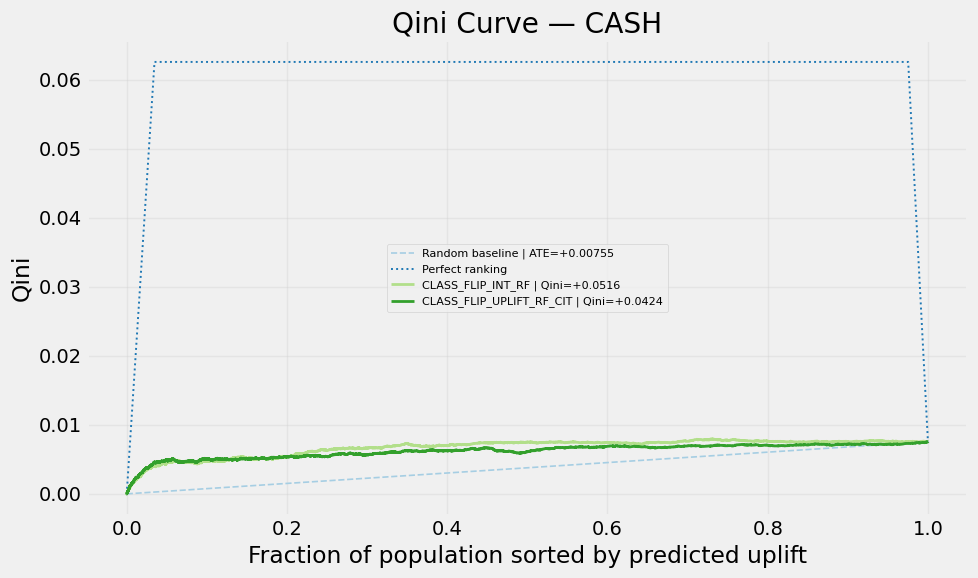

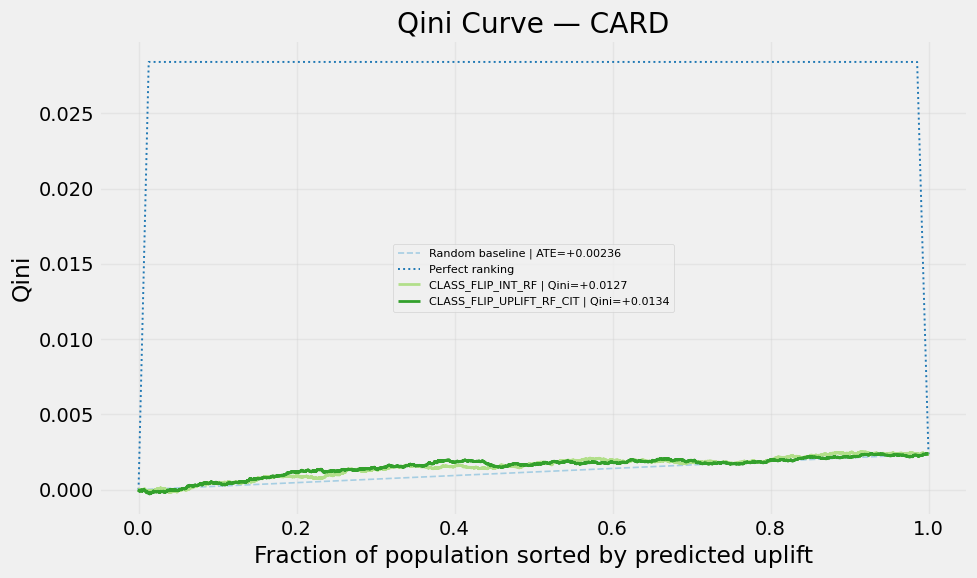

In [12]:
# ============================================================
# 11. QINI CURVES
# ============================================================
def plot_qini_compare(target_name, y, w_event, score_dict):
    if not score_dict:
        print(f"No scores for {target_name}")
        return

    plt.figure(figsize=(10, 6))
    xp, qp = qini_curve(y, w_event, oracle_score(y, w_event))
    ate = qp[-1]
    plt.plot([0, 1], [0, ate], "--", linewidth=1.2, label=f"Random baseline | ATE={ate:+.5f}")
    plt.plot(xp, qp, ":", linewidth=1.4, label="Perfect ranking")

    for model_name, score in score_dict.items():
        x, q = qini_curve(y, w_event, score)
        m = qini_metrics(y, w_event, score)
        plt.plot(x, q, linewidth=2, label=f"{model_name} | Qini={m['qini_norm']:+.4f}")

    plt.title(f"Qini Curve — {target_name.upper()}")
    plt.xlabel("Fraction of population sorted by predicted uplift")
    plt.ylabel("Qini")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_qini_compare("cash", Y_cash, w_cash, scores_oof["cash"])
plot_qini_compare("card", Y_card, w_card, scores_oof["card"])


## 8. Export outputs

In [13]:
# ============================================================
# 12. EXPORT OUTPUTS
# ============================================================
def _safe_run_name(text, max_len=80):
    text = "baseline_all_features" if text is None else str(text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", text)
    return text[:max_len].strip("_") or "run"


BASE_OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
if not FEATURE_DROP_BASE_COLS:
    RUN_TAG = "baseline_all_features"
else:
    id_part = "ids_" + "-".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)
    name_part = _safe_run_name("__".join(FEATURE_DROP_BASE_COLS), max_len=100)
    RUN_TAG = f"drop_{id_part}_{name_part}"

OUTPUT_DIR = BASE_OUTPUT_DIR / RUN_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR)

summary_path = OUTPUT_DIR / "qini_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

fold_path = OUTPUT_DIR / "fold_qini_logs.csv"
fold_qini_logs.to_csv(fold_path, index=False)
print("Saved:", fold_path)

fold_mean_path = OUTPUT_DIR / "fold_mean_qini_by_model.csv"
fold_mean_qini_by_model.to_csv(fold_mean_path, index=False)
print("Saved:", fold_mean_path)

run_log_df = pd.DataFrame(run_log)
run_log_path = OUTPUT_DIR / "run_log.csv"
run_log_df.to_csv(run_log_path, index=False)
print("Saved:", run_log_path)

train_id = make_id_series(feat, id_col=ID_COL)

oof_out = pd.DataFrame()
oof_out[train_id.name] = train_id.values
oof_out["treatment_cash"] = W
oof_out["cash_sign_30d"] = Y_cash
oof_out["card_sign_30d"] = Y_card
oof_out["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
oof_out["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
oof_out["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
for name, score in scores_oof["cash"].items():
    oof_out[f"cash_{name}"] = score
for name, score in scores_oof["card"].items():
    oof_out[f"card_{name}"] = score

oof_path = OUTPUT_DIR / "oof_model_scores.csv"
oof_out.to_csv(oof_path, index=False)
print("Saved:", oof_path)

if best_model is not None:
    final_train = pd.DataFrame()
    final_train[train_id.name] = train_id.values
    final_train["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
    final_train["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
    final_train["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
    final_train["best_model"] = best_model
    final_train["uplift_cash_score"] = scores_oof["cash"][best_model]
    final_train["uplift_card_score"] = scores_oof["card"][best_model]
    final_train["cash_vs_card_score"] = final_train["uplift_cash_score"] - final_train["uplift_card_score"]
    final_train["recommended_product"] = np.where(final_train["cash_vs_card_score"] >= 0, "Cash", "Card")

    final_train_path = OUTPUT_DIR / "final_scores_train.csv"
    final_train.to_csv(final_train_path, index=False)
    print("Saved:", final_train_path)

    if X_test is not None and best_model in scores_test["cash"] and best_model in scores_test["card"]:
        submission = pd.DataFrame()
        submission[test_id.name] = test_id.values
        submission["best_model"] = best_model
        submission["uplift_cash_score"] = scores_test["cash"][best_model]
        submission["uplift_card_score"] = scores_test["card"][best_model]
        submission["cash_vs_card_score"] = submission["uplift_cash_score"] - submission["uplift_card_score"]
        submission["recommended_product"] = np.where(submission["cash_vs_card_score"] >= 0, "Cash", "Card")

        submission_path = OUTPUT_DIR / "submission.csv"
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path)
    else:
        print("Skip submission: không có X_test hoặc best_model không có test score.")
else:
    print("Skip final score export: không có best_model.")

feature_drop_result = {
    "COL_IDX_config": str(COL_IDX),
    "feature_drop_col_idx": FEATURE_DROP_COL_IDX,
    "feature_drop_base_col": FEATURE_DROP_BASE_COL,
    "n_feature_drop_base_cols": len(FEATURE_DROP_BASE_COLS),
    "feature_drop_base_cols": "|".join(FEATURE_DROP_BASE_COLS),
    "n_dropped_train_cols": len(drop_cols_in_feat),
    "dropped_train_cols": "|".join(drop_cols_in_feat),
    "n_features_after_drop": len(FEAT_COLS),
    "best_model": best_model,
}
if best_model is not None:
    best_row = summary.iloc[0].to_dict()
    feature_drop_result.update({
        "best_Qini_coefficient_cash": best_row["Qini_coefficient_cash"],
        "best_Qini_coefficient_card": best_row["Qini_coefficient_card"],
        "best_Qini_coefficient_total": best_row["Qini_coefficient_total"],
    })

feature_drop_result_path = OUTPUT_DIR / "feature_drop_result.csv"
pd.DataFrame([feature_drop_result]).to_csv(feature_drop_result_path, index=False)
print("Saved:", feature_drop_result_path)


Output dir: /kaggle/working/baseline_all_features
Saved: /kaggle/working/baseline_all_features/qini_summary.csv
Saved: /kaggle/working/baseline_all_features/fold_qini_logs.csv
Saved: /kaggle/working/baseline_all_features/fold_mean_qini_by_model.csv
Saved: /kaggle/working/baseline_all_features/run_log.csv
Saved: /kaggle/working/baseline_all_features/oof_model_scores.csv
Saved: /kaggle/working/baseline_all_features/final_scores_train.csv
Skip submission: không có X_test hoặc best_model không có test score.
Saved: /kaggle/working/baseline_all_features/feature_drop_result.csv


## 9. Cách đọc kết quả

Các file quan trọng sau khi chạy:

- `qini_summary.csv`: Qini OOF của **CLASS_FLIP_INT_RF** và **CLASS_FLIP_UPLIFT_RF_CIT**.
- `fold_qini_logs.csv`: Qini từng fold cho từng model.
- `fold_mean_qini_by_model.csv`: Qini trung bình 5 fold.
- `run_log.csv`: log thời gian chạy và lỗi nếu model nào bị skip.
- `feature_drop_result.csv`: file gọn nhất để so sánh các lần drop feature; đã hỗ trợ drop nhiều feature một lúc qua `COL_IDX = [2, 3, 4, 5]`, `list(range(2, 6))`, hoặc `"2:6"`.
- `oof_model_scores.csv`: score OOF của các model Class Flipping.
- `final_scores_train.csv`: score uplift Cash/Card và khuyến nghị Cash/Card trên train theo best model.
- `submission.csv`: chỉ tạo nếu notebook tìm thấy test feature đã clean/one-hot tương thích với `df_feature.csv`.

Lưu ý:

- Class flipping chỉ được áp dụng trên train fold.
- Validation fold/test giữ nguyên phân phối thật để Qini không bị lệch.
- Nếu `CLASS_FLIP_UPLIFT_RF_CIT` bị skip do thiếu `causalml`, bật `RUN_INSTALL_CAUSALML=True` ở cell đầu tiên rồi chạy lại notebook.
